### ASTR 3300/5300: Astrostatistics
***N. Pol***
___

# Homework 6
### Due: Wed. Nov 4, at 11.59pm CT
---

This problem has to do with density estimation and clustering. 

1. Read in `hw6_data_1.npy`. The dataset should consist of $1000$ samples with $2$ features. Note that the last column are the labels, not another feature. Make a $2$-D scatter plot of the data colored by their labels. 


2. Start with kernel density estimation on the data set. First, perform a grid search $5$-fold cross-validation to find the best bandwidth, testing $30$ bandwidths between $0.1$ and $1.0$. What is this best bandwidth? Using this best bandwidth, plot the two-dimensional kernel density estimate of the distribution. 


3. Now try a nearest neighbors approach to estimating the density. Use the Bayesian nearest neighbors option. Plot the estimated distribution. What value of $k$ neighbors do you need to make the plot look similar to your KDE distribution?


4. Now fit a Gaussian mixture model. Compute the AIC and BIC for the number of GMM components between $1$ and $10$. Plot these AIC and BIC values as a function of number of components. What is the optimal number according to the BIC? Fit the data set with this optimal number of GMM components, and create a new plot that shows the data set, the GMM component mean locations, and the $2$-sigma GMM component ellipses. *(Use the code below to help with plotting the ellipses.)*

In [1]:
# Kludge to fix the bug with draw_ellipse in astroML
from matplotlib.patches import Ellipse

def draw_ellipse(mu, C, scales=[1, 2, 3], ax=None, **kwargs):
    if ax is None:
        ax = plt.gca()

    # find principal components and rotation angle of ellipse
    sigma_x2 = C[0, 0]
    sigma_y2 = C[1, 1]
    sigma_xy = C[0, 1]

    alpha = 0.5 * np.arctan2(2 * sigma_xy,
                          (sigma_x2 - sigma_y2))
    tmp1 = 0.5 * (sigma_x2 + sigma_y2)
    tmp2 = np.sqrt(0.25 * (sigma_x2 - sigma_y2) ** 2 + sigma_xy ** 2)

    sigma1 = np.sqrt(tmp1 + tmp2)
    sigma2 = np.sqrt(tmp1 - tmp2)

    for scale in scales:
        ax.add_patch(Ellipse(xy=(mu[0], mu[1]),
                          width=2 * scale * sigma1, height=2 * scale * sigma2,
                          angle=alpha * 180. / np.pi,
                          **kwargs))

5. Now try Kmeans clustering with $5$ clusters. 
    - Use the `StandardScalar` to scale the data.
    - Fit the Kmeans model.
    - Find the cluster centers, and then inverse transform thse cluster centers back to the original unscaled coordinates.
    - Predict the labels for the scaled data.
    - Finally, make a two-panel side by side plot showing (a) the original data colored by its labels, then (b) the data colored by the Kmeans predicted labels, with cluster centers superposed.

### Solution

In [93]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load("/Users/jhorna/astrostats_ttu_fall26/coursework/homeworks/hw_data/hw6_data_1.npy")
print(data.shape)

(1000, 3)


**1.**

In [94]:
X = data[:, :2]
y = data[:, 2]

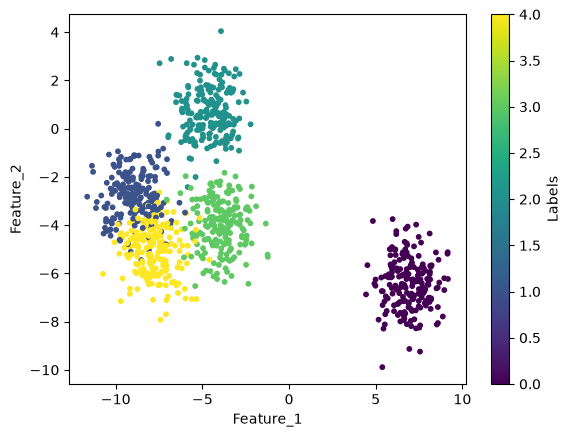

In [95]:
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', s=10)
plt.xlabel('Feature_1')
plt.ylabel('Feature_2')
plt.colorbar(label='Labels')
plt.show()

**2.**

In [96]:
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV

bandwidths = np.linspace(0.1, 1.0, 30)

grid = GridSearchCV(
    KernelDensity(kernel='gaussian'),
    {'bandwidth': bandwidths},
    cv=5
)

grid.fit(X)

print("Best bandwidth:", grid.best_params_['bandwidth'])

Best bandwidth: 0.4724137931034482


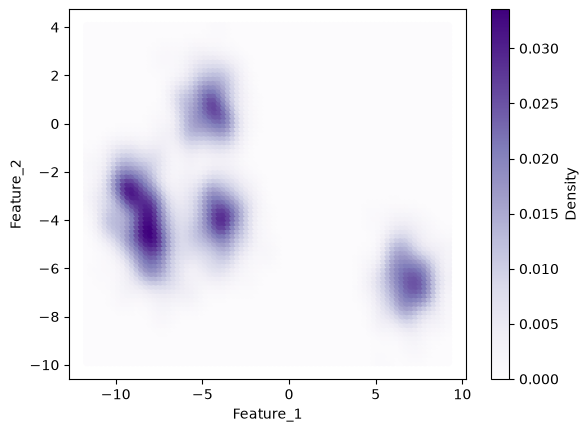

In [119]:
kde = KernelDensity(kernel='gaussian', bandwidth=grid.best_params_['bandwidth'])
kde.fit(X)

u = np.linspace(X[:, 0].min(), X[:, 0].max(), 80)
v = np.linspace(X[:, 1].min(), X[:, 1].max(), 80)

Xgrid = np.vstack(list(map(np.ravel, np.meshgrid(u, v)))).T

dens = np.exp(kde.score_samples(Xgrid))

plt.scatter(Xgrid[:, 0], Xgrid[:, 1], c=dens,
            cmap="Purples", edgecolor="None")
plt.colorbar(label='Density')
plt.xlabel('Feature_1')
plt.ylabel('Feature_2')
plt.show()

**3.**

In [117]:
from astroML.density_estimation import KNeighborsDensity

k = 80

nebrs = KNeighborsDensity('bayesian', n_neighbors=k)
nebrs.fit(X)

dens_nebrs = nebrs.eval(Xgrid) / len(X)

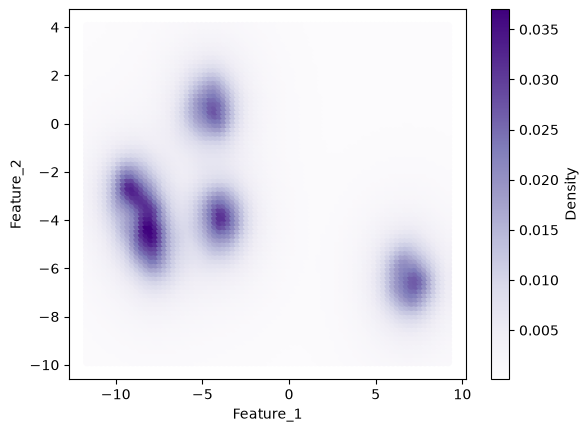

In [118]:
plt.scatter(Xgrid[:, 0], Xgrid[:, 1], c=dens_nebrs,
            cmap="Purples", edgecolor="None")
plt.colorbar(label='Density')
plt.xlabel('Feature_1')
plt.ylabel('Feature_2')
plt.show()

ncreasing the value of $k$ beyond 80 does not noticeably change the distribution. At $k=80$, the nearest-neighbor density estimate already looks similar to the KDE distribution. 

**4.**

In [100]:
from sklearn.mixture import GaussianMixture

n_components = np.arange(1, 11)

AIC = []
BIC = []

for n in n_components:
    gmm = GaussianMixture(n_components=n, random_state=42)
    gmm.fit(X)

    AIC.append(gmm.aic(X))
    BIC.append(gmm.bic(X))

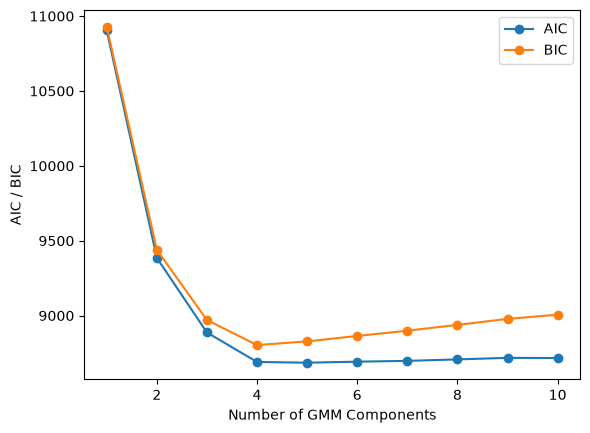

In [101]:
plt.plot(n_components, AIC, 'o-', label='AIC')
plt.plot(n_components, BIC, 'o-', label='BIC')

plt.xlabel('Number of GMM Components')
plt.ylabel('AIC / BIC')
plt.legend()
plt.show()

In [120]:
print("Best BIC components:", n_components[np.argmin(BIC)])
print("Best AIC components:", n_components[np.argmin(AIC)])

Best BIC components: 4
Best AIC components: 5


The BIC reaches its minimum at 4 components, while the AIC reaches its minimum at 5 components. Therefore, the optimal number of GMM components according to BIC is 4.

In [102]:
best_gmm = GaussianMixture(n_components=4, random_state=42)
best_gmm.fit(X)

means = best_gmm.means_
covariances = best_gmm.covariances_

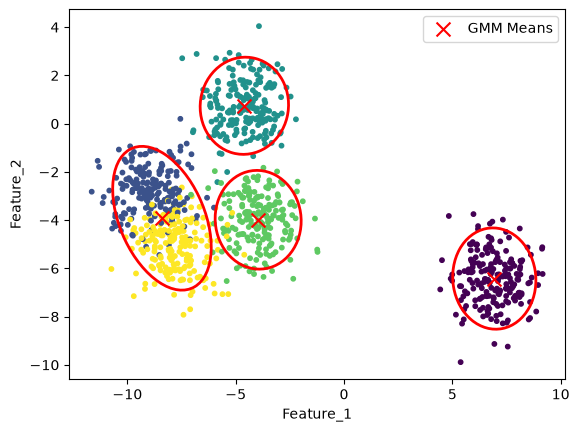

In [109]:
fig, ax = plt.subplots()

ax.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', s=10)

ax.scatter(means[:, 0], means[:, 1],
           c='red', marker='x', s=100, label='GMM Means')

for i in range(4):
    draw_ellipse(means[i], covariances[i],
                 scales=[2], ax=ax,
                 edgecolor='red', facecolor='none', linewidth=2)

ax.set_xlabel('Feature_1')
ax.set_ylabel('Feature_2')
ax.legend()
plt.show()

**5.**

In [110]:
from sklearn import preprocessing

scaler = preprocessing.StandardScaler()
X_scaled = scaler.fit_transform(X)

In [111]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 2)","[[-0.

In [112]:
centers_scaled = kmeans.cluster_centers_
centers = scaler.inverse_transform(centers_scaled)

In [113]:
labels_pred = kmeans.predict(X_scaled)

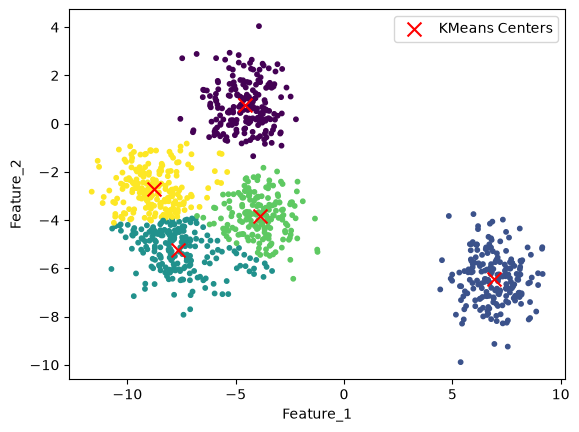

In [114]:
plt.scatter(X[:, 0], X[:, 1], c=labels_pred, cmap='viridis', s=10)

plt.scatter(centers[:, 0], centers[:, 1],
            c='red', marker='x', s=100, label='KMeans Centers')

plt.xlabel('Feature_1')
plt.ylabel('Feature_2')
plt.legend()
plt.show()

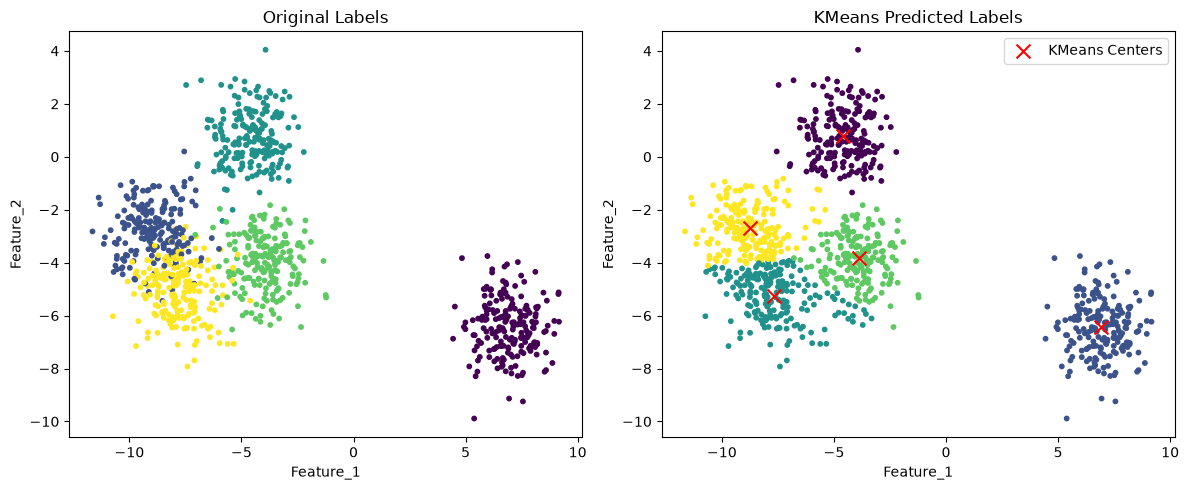

In [116]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', s=10)
ax[0].set_title('Original Labels')
ax[0].set_xlabel('Feature_1')
ax[0].set_ylabel('Feature_2')

ax[1].scatter(X[:, 0], X[:, 1], c=labels_pred, cmap='viridis', s=10)
ax[1].scatter(centers[:, 0], centers[:, 1],
              c='red', marker='x', s=100, label='KMeans Centers')
ax[1].set_title('KMeans Predicted Labels')
ax[1].set_xlabel('Feature_1')
ax[1].set_ylabel('Feature_2')
ax[1].legend()

plt.tight_layout()
plt.show()